# Lab 1: What Do the Weights of a Neural Network Actually Represent?

**MNIST internals series** — the practical companion to the [ML notes](/posts/ml/) (softmax & cross-entropy, backprop, training a 2-layer network). This time we stop deriving and start *looking*.

Anyone who has trained a model eventually asks:

> The model is just a pile of numbers. In this lab's case, exactly 7,860 of them (7,850 weights + 10 biases). **What do those numbers actually *mean*?**

For a large model, nobody knows the full answer — that is the open problem of [mechanistic interpretability](https://distill.pub/2017/feature-visualization/). But for the smallest useful classifier — one softmax layer over raw MNIST pixels — the answer is **complete, exact, and visible**. By the end of this lab we will have:

1. trained a softmax classifier on MNIST from scratch (pure NumPy, gradients checked numerically),
2. saved weight **checkpoints** all through training and watched each weight row turn into a picture,
3. decomposed a single prediction into per-pixel *votes for / votes against*,
4. catalogued its failures and explained them mechanism-first.

The claim to test as we go: **each row of $W$ is a learned photograph of a digit class** — a *matched filter* — and the score a class gets is the pixel-by-pixel overlap between the input and that photograph. Training is the act of averaging thousands of pictures of a "7" into one idealized "7", while erasing ink wherever rival digits tend to draw.

No framework. When the model is this small, hiding the arithmetic would hide the very thing we came to see.

## 0. Setup

Everything lives in `labs/ml/mnist-internals/`:

```
mnist_lab/     shared helpers: IDX parsing, plotting, checkpoint bookkeeping
data/          raw MNIST files (LeCun's IDX format, downloaded automatically)
checkpoints/   weight snapshots saved by the notebooks (.npz + manifest.json)
figures/       every figure exported as PNG
```

MNIST ships in the **IDX binary format**: a 4-byte magic number (encoding dtype + rank), big-endian dimension sizes, then raw bytes. Our loader parses it with `struct` + `numpy` — no torchvision, no magic.

In [1]:
from pathlib import Path
import sys, time
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams["figure.dpi"] = 110

from mnist_lab import (
    load_mnist, show_grid, show_confusion, save_fig,
    save_ckpt, load_ckpt, manifest, one_hot,
)

print("python:", sys.version.split()[0], "| numpy:", np.__version__)
print("cwd   :", Path.cwd())

rng = np.random.default_rng(42)
x_train, y_train, x_test, y_test = load_mnist("data")

CKPT = Path("checkpoints/lab01")
FIGS = Path("figures/lab01"); FIGS.mkdir(parents=True, exist_ok=True)

print("train:", x_train.shape, " test:", x_test.shape)
print("pixel range:", x_train.min(), "...", x_train.max(),
      "| exactly-zero pixels:", f"{(x_train == 0).mean():.0%}")

python: 3.14.3 | numpy: 2.5.4
cwd   : /Users/sanketh.bk/sanketh/blog/labs/ml/mnist-internals


train: (60000, 784)  test: (10000, 784)


pixel range: 0.0 ... 1.0 | exactly-zero pixels: 81%


## 1. Meet the data: a digit is a point in $\mathbb{R}^{784}$

A 28×28 image flattened is a vector of 784 ink intensities scaled to $[0,1]$. ~80% of entries are pure background — the information is sparse and structured, which is why random vectors in $\mathbb{R}^{784}$ are *not* digits and why a classifier has room to exist at all.

Below: random samples, and the **class-conditional mean image** $\bar{x}_c$ = average of every training "$c$". The means are the *obvious* prototypes of each digit. Keep them in mind — we will compare them against the trained weights shortly, and the difference between the two is the whole story of this lab.

saved figure -> figures/lab01/samples.png


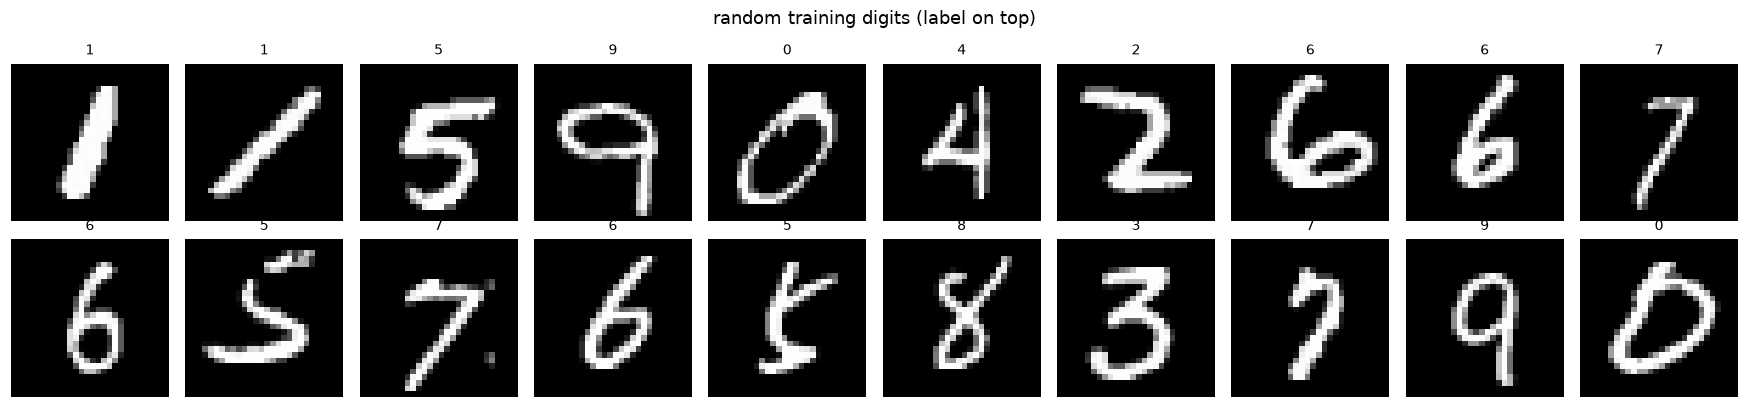

saved figure -> figures/lab01/class_means.png


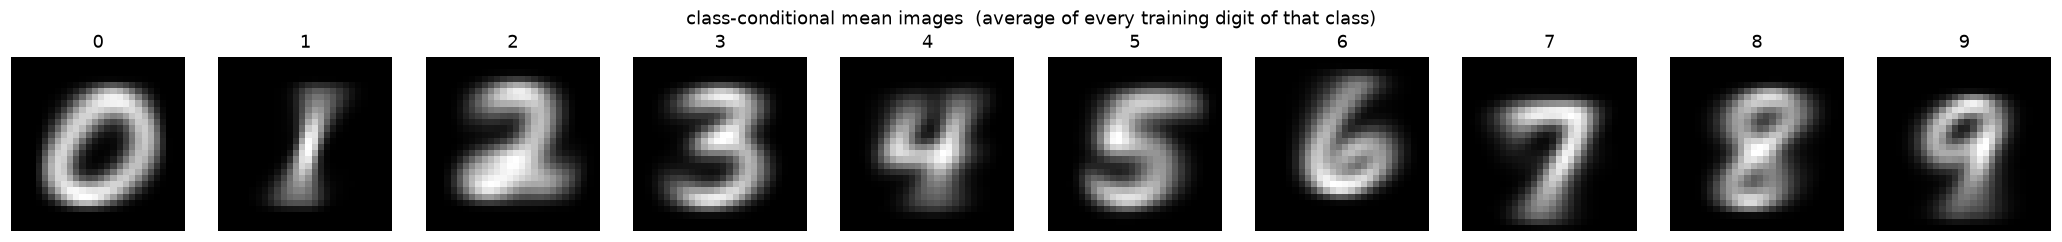

train counts per class: {0: np.int64(5923), 1: np.int64(6742), 2: np.int64(5958), 3: np.int64(6131), 4: np.int64(5842), 5: np.int64(5421), 6: np.int64(5918), 7: np.int64(6265), 8: np.int64(5851), 9: np.int64(5949)}


In [2]:
idx = rng.integers(0, len(x_train), 20)
fig = show_grid(x_train[idx], titles=y_train[idx], ncols=10, suptitle="random training digits (label on top)")
save_fig(fig, FIGS / "samples.png"); plt.show()

means = np.stack([x_train[y_train == c].mean(0) for c in range(10)])
fig, axes = plt.subplots(1, 10, figsize=(19, 2.2))
for c, ax in enumerate(axes):
    ax.imshow(means[c].reshape(28, 28), cmap="gray")
    ax.set_title(str(c)); ax.axis("off")
fig.suptitle("class-conditional mean images  (average of every training digit of that class)")
fig.tight_layout()
save_fig(fig, FIGS / "class_means.png"); plt.show()

print("train counts per class:", dict(enumerate(np.bincount(y_train))))

## 2. The model: one matrix multiply, then softmax

**Forward:** logits $z = Wx + b$, with $W \in \mathbb{R}^{10 \times 784}$ and $b \in \mathbb{R}^{10}$; probabilities $\hat p = \mathrm{softmax}(z)$; loss = mean cross-entropy $\mathcal{L} = -\tfrac1N \sum_i \log \hat p_{i,\,y_i}$.

> The type of neural network we are going to use here is just one layer: input layer with 784 neurons and output consists of 10 output nodes (not neurons technically) - they softmax the output. 
>
>      It's the smallest possible "neural network": one weight layer, zero hidden layers (softmax regression).
> 
>     - Layer 0 — input: 784 neurons, one per pixel (not trainable).
>     - Layer 1 — output: 10 neurons, one per digit. Each has 784 weights (its row of W) + 1 bias = 785 params.
>     - Total: 10 × 785 = 7,850 weights + 10 biases = 7,860 numbers, matching the notebook.


<img src="../../../assets/images/handwritten_digits_single_layer_neural_network.png" width="600">

>  **Why it still works:** 
> MNIST digits really are mostly separable as pixel clouds. A linear model on raw pixels gets ~92.6%, which is respectable but it's the ceiling — the ~7% it can't get are stroke-connectivity cases (5 vs 3, 7 vs 9) that need features, not pixels.

> On 3b1b: his net is 784 → 16 → 16 → 10 with ReLU — two hidden layers, ~13k params, 98%. So the extra layers buy 5–6 accuracy points. The tradeoff is exactly what §7 says: as soon as a hidden layer exists, the input→hidden rows stop being class photos and become parts (edges, strokes), and you can no longer read them as digits.

> So: is it built this way to visualize? *Mostly yes, deliberately*. The design principle is "strip away everything that hides the arithmetic." Keeping the input as the feature space is the one trick that makes weights renderable as images.

> But it's also the natural first model to try — the pedagogical and the honest choice coincide here. Lab 3 is where you pay for the hidden layers and lose the pictures.

**Gradient** (derived in the [softmax note](/posts/ml/2026-09-14-3-softmax-and-multiclass-cross-entropy)) — the single most important equation in this lab:

> The most important result from the softmax lesson was $∂L/∂z_i = p_i − y_i$ i.e., even softmax appears to be mixing z's and creating complex functions, the dependencies cancel out and the derivate of logit is purely dependent on its output and its label
>
> Single example. $z_c = Σ_j W_{cj} x_j + b_c$, so
>
> $∂z_c/∂W_{cj} = x_j$        
> $∂z_c/∂b_c = 1$
>
> and nothing else in $W$ affects $z_c$. Therefore
> 
> $∂L/∂W_{cj} = (∂L/∂z_c) · x_j = (p_c − y_c) x_j$
> 
> $∂L/∂b_c    = (p_c − y_c) · 1$

$$\frac{\partial \mathcal{L}}{\partial W} = \tfrac1N (\hat p - y)\, x^\top, \qquad \frac{\partial \mathcal{L}}{\partial b} = \tfrac1N (\hat p - y)$$

For **one image**, the gradient is:


$$
\frac{\partial \ell}{\partial W}
= \frac{\partial \ell}{\partial z}\frac{\partial z}{\partial W}
= (\hat p-y)x^\top
$$

Here’s why the $x^\top$ appears. For class $c$ and pixel $j$,

$$
z_c=\sum_j W_{cj}x_j+b_c
\quad\Longrightarrow\quad
\frac{\partial z_c}{\partial W_{cj}}=x_j.
$$

So each weight’s gradient is the class’s logit error, $(\hat p_c-y_c)$, multiplied by that pixel’s value, $x_j$. Putting all classes and pixels into a matrix gives the **outer product**:

$$
(\hat p-y)x^\top
$$

The shapes make this concrete: $(\hat p-y)$ is $10\times1$, and $x^\top$ is $1\times784$, so their product is $10\times784$—the same shape as $W$.

For **$N$ images**, the loss is the average of their individual losses:

$$
\mathcal L=\frac{1}{N}\sum_{i=1}^{N}\ell_i.
$$

Differentiating an average means averaging the individual gradients:

$$
\frac{\partial\mathcal L}{\partial W}
=\frac{1}{N}\sum_{i=1}^{N}(\hat p_i-y_i)x_i^\top.
$$

That’s where $1/N$ comes from. It keeps the gradient on the scale of an average example, rather than making it grow just because the batch is larger.

For a batch, the notebook’s equivalent matrix form is:

$$
\frac{\partial\mathcal L}{\partial W}
=\frac{1}{N}\Delta^\top X,
$$

where each row of $X$ is one image and each row of $\Delta$ is that image’s $(\hat p-y)$.

Now read the SGD update $W \leftarrow W - \eta\,\partial \mathcal{L} / \partial W$ literally:

> Every training image $x$ **paints itself into every row of $W$**. The true class's row *gains* $(1 - \hat p_c)\,x$; every wrong class's row *loses* $\hat p_c\,x$.

### What that update looks like for one pixel

Take one image whose correct label is **7**, and look at one pixel with value $x_j=1$. Suppose the model currently assigns probability $0.7$ to 7 and $0.2$ to 1. For this pixel, the gradient is $(\hat p_c-y_c)x_j$:

- **Digit 7 (the correct class):** $(0.7-1)\times1=-0.3$. Gradient descent subtracts the gradient, so this weight **increases by $0.3\eta$**.
- **Digit 1 (a wrong class):** $(0.2-0)\times1=0.2$. Subtracting this gradient makes this weight **decrease by $0.2\eta$**.

Here $\eta$ is the learning rate. Increasing the 7 weight makes this pixel count more in favor of 7 next time; decreasing the 1 weight makes it count less in favor of 1. If the pixel value were zero, this example would make no change to either class's weight for that pixel. For a dim pixel such as $x_j=0.5$, both changes would be half as large.

That is all “the image paints itself into the rows” means: each pixel changes the corresponding weight according to its intensity and how wrong the current probabilities were. Across a mini-batch, the changes from its images are averaged. If the model already gives the correct digit almost all the probability, the gradients are close to zero, so the weights barely change.

So training is: *true-class rows accumulate the average ink of their class; wrong-class rows accumulate negative ink of everything that tempted them.* If an image is predicted perfectly, $\hat p - y \approx 0$ and it stops painting entirely.

Before training anything, we verify our analytic gradient against finite differences — on a tiny 8-image batch in `float64`. If the numbers match, the code implements the math, not just *a* math.


**What this check does:** A derivative is the slope of the loss as one parameter changes. For a selected weight, the code nudges it slightly up and down by $\varepsilon$, measures the loss both times, and estimates the slope as $[L(W+\varepsilon)-L(W-\varepsilon)]/(2\varepsilon)$. This is the central finite-difference approximation to the derivative from first principles. It compares that numerical estimate with the gradient formula in `grad()`. Close values are evidence that the implemented formula is correct for this model and loss. We check a small sample of weights rather than all 7,840, and use `float64` so rounding does not overwhelm the tiny nudges.

### A useful mental model to carry forward

Each output class has its own row of 784 pixel weights and one bias (785 parameters total). For an image, backprop updates every class row, not only the row for the correct answer. It pushes the correct class to score the image higher, and pushes the other classes to score it lower. A wrong class that gave the image a high probability gets a stronger corrective push.

So a class learns both which pixel patterns tend to support its score and which patterns tend to mislead it. The weights are not literal stored examples or perfect pictures of digits; they are coefficients the model adjusts based on its errors.



In [3]:
class SoftmaxReg:
    """z = x @ W.T + b ; p = softmax(z) ; cross-entropy loss ; plain SGD."""
    def __init__(self, n_in, n_classes, rng, scale=0.01):
        self.W = rng.normal(0, scale, size=(n_classes, n_in))   # float64
        self.b = np.zeros(n_classes)

    def logits(self, x):
        return x @ self.W.T + self.b

    def probs(self, x):
        z = self.logits(x)
        z = z - z.max(axis=1, keepdims=True)          # stability: softmax(z) == softmax(z - c)
        e = np.exp(z)
        return e / e.sum(axis=1, keepdims=True)

    def loss(self, x, y):
        p = self.probs(x)
        return float(-np.log(p[np.arange(len(y)), y] + 1e-12).mean())

    def grad(self, x, y):
        p = self.probs(x)
        delta = p - one_hot(y, self.W.shape[0])        # (n, k)
        return delta.T @ x / len(y), delta.mean(axis=0)

    def step(self, x, y, lr):
        gW, gb = self.grad(x, y)
        self.W -= lr * gW
        self.b -= lr * gb

    def predict(self, x):
        return self.logits(x).argmax(axis=1)

    def accuracy(self, x, y):
        return float((self.predict(x) == y).mean())


# --- numerical gradient check (central differences) on an 8-image mini-batch ---
xt, yt = x_train[:8].astype(np.float64), y_train[:8]
m = SoftmaxReg(784, 10, np.random.default_rng(0))
gW, gB = m.grad(xt, yt)

eps, errs = 1e-6, []
for flat in np.random.default_rng(1).integers(0, 10 * 784, size=25):
    i, j = divmod(int(flat), 784)
    orig = m.W[i, j]
    m.W[i, j] = orig + eps; lp = m.loss(xt, yt)
    m.W[i, j] = orig - eps; lm = m.loss(xt, yt)
    m.W[i, j] = orig
    errs.append(abs(gW[i, j] - (lp - lm) / (2 * eps)) / (1e-12 + abs(gW[i, j]) + abs((lp - lm) / (2 * eps))))
print(f"max relative error over {len(errs)} randomly probed weights: {max(errs):.2e}")
print("-> tiny error means our dL/dW is the gradient of THIS code, not of an idealization")

max relative error over 25 randomly probed weights: 3.53e-08
-> tiny error means our dL/dW is the gradient of THIS code, not of an idealization


## 3. Training — with the camera rolling

Mini-batch SGD: batch 256, lr 0.5, 5 epochs ≈ 1,170 steps. We save a **checkpoint** of $(W, b)$ at steps 0, 1, 2, 5, 10, 25, 50, 100, 200, 400, 800 and at the end — each with the test accuracy it had reached. The accuracy curve tells you *what it knows*; the snapshots tell you *what it is*.

### Epochs, batches, and steps

A **batch** is the group of examples used to calculate one gradient update. A **step** is that one update. An **epoch** is one pass through the training set, usually after shuffling and splitting the examples into batches:

```text
one training step:
    take one batch of examples
    calculate predictions and gradients for that batch
    update the model's weights once

one epoch:
    shuffle the training examples
    split them into batches
    run one training step per batch
    # The model has seen each training example once
```

This notebook uses batches of 256, so it runs about 234 steps per epoch. The code drops the final incomplete batch, so a small remainder is not seen during that epoch.

### Mini-batch SGD and full-batch gradient descent

The name **stochastic gradient descent (SGD)** is used in two ways. Strictly, SGD uses one example per update. In everyday machine-learning usage, “SGD” often also refers to mini-batch training like this notebook, where each update uses a small group of examples.

- **Single-example SGD:** calculate an update from one example at a time. Each update is cheap and needs little memory, and the model updates frequently. But individual examples can point in different directions, so the loss may jump around rather than decrease smoothly.
- **Mini-batch SGD (this lab):** average the gradients from a batch, then update once. This reduces some of the single-example noise while keeping updates manageable and efficient on typical hardware. The gradient is still an estimate based on part of the dataset, so it can fluctuate.
- **Full-batch gradient descent:** calculate one gradient using the entire training dataset, then update once. That gives a less noisy estimate of the dataset-wide direction, but each update takes more computation and memory. An epoch is only one update, so reaching a useful solution may require fewer but more expensive steps.

With batch size 1, one epoch over 60,000 examples means about 60,000 updates. With full-batch training, it means one update. Mini-batches are a practical middle ground: in this notebook, 256 examples per update means about 234 updates per epoch.


In [4]:
BATCH, LR, EPOCHS = 256, 0.5, 5
snapshot_steps = {0, 1, 2, 5, 10, 25, 50, 100, 200, 400, 800}
n_steps = EPOCHS * (len(x_train) // BATCH)

model = SoftmaxReg(784, 10, rng)
snapshots, hist = {}, []

def snapshot(step):
    snapshots[step] = model.W.copy()
    acc_te = model.accuracy(x_test, y_test)
    hist.append((step, model.loss(x_train[::25], y_train[::25]), acc_te))
    save_ckpt(CKPT, f"step_{step:05d}", step=step,
              metrics={"test_acc": round(acc_te, 4)}, W=model.W, b=model.b)

snapshot(0)          # random initialization
t0 = time.perf_counter()
step = 0
for epoch in range(EPOCHS):
    perm = rng.permutation(len(x_train))
    perm = perm[: len(perm) // BATCH * BATCH]   # drop the remainder batch
    for batch_idx in perm.reshape(-1, BATCH):
        model.step(x_train[batch_idx], y_train[batch_idx], LR)
        step += 1
        if step in snapshot_steps or step == n_steps:
            snapshot(step)
    print(f"epoch {epoch + 1}/{EPOCHS}:  test acc = {model.accuracy(x_test, y_test):.4f}")

final_acc = model.accuracy(x_test, y_test)
print(f"\n{step} steps in {time.perf_counter() - t0:.1f}s | final test accuracy: {final_acc:.4f}")

epoch 1/5:  test acc = 0.9103


epoch 2/5:  test acc = 0.9129


epoch 3/5:  test acc = 0.9180


epoch 4/5:  test acc = 0.9199


epoch 5/5:  test acc = 0.9209

1170 steps in 24.4s | final test accuracy: 0.9209


saved figure -> figures/lab01/training_curve.png


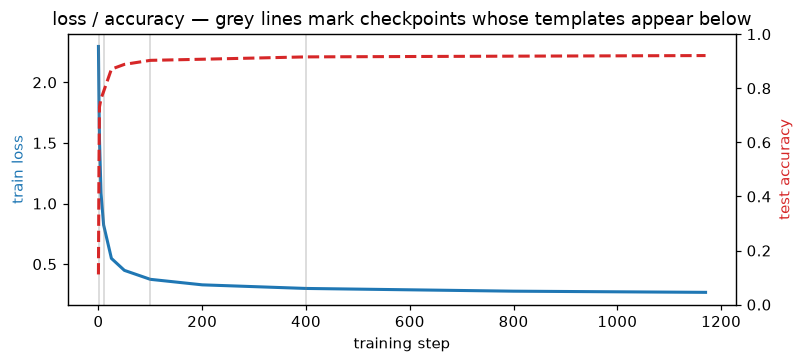

In [5]:
h = np.array(hist)
fig, ax1 = plt.subplots(figsize=(7.5, 3.4))
ax1.plot(h[:, 0], h[:, 1], color="tab:blue", lw=2)
ax1.set_xlabel("training step"); ax1.set_ylabel("train loss", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(h[:, 0], h[:, 2], color="tab:red", lw=2, ls="--")
ax2.set_ylabel("test accuracy", color="tab:red"); ax2.set_ylim(0, 1)
for s in (1, 10, 100, 400):
    ax1.axvline(s, color="grey", alpha=.35, lw=1)
ax1.set_title("loss / accuracy — grey lines mark checkpoints whose templates appear below")
fig.tight_layout()
save_fig(fig, FIGS / "training_curve.png"); plt.show()

## 4. The reveal: the weights are photographs

A row $W_c$ has 784 numbers. Reshape it to 28×28 and render it with a **diverging colormap**: <span style="color:#2166ac">blue = ink here votes FOR the class</span>, <span style="color:#b2182b">red = ink here votes AGAINST it</span>, white = irrelevant. (A negative weight is not "unused" — it is active suppression, and it is half of what the matrix learned.)

Compare the trained rows against the class means from §1 — same sea, different fish. And per the cosine printout: a template is NOT the mean image (cos ≈ 0.3, not 1.0). It is the mean **minus a red halo of its lookalikes** — the center of the "0" template is deep red because "1"s live there; the "9" template suppresses the whole lower left, which is "7" and "4" territory. The painting rule from §2 makes this inevitable: every rival image that ever fooled the class painted red ink where it draws.

saved figure -> figures/lab01/templates_vs_means.png


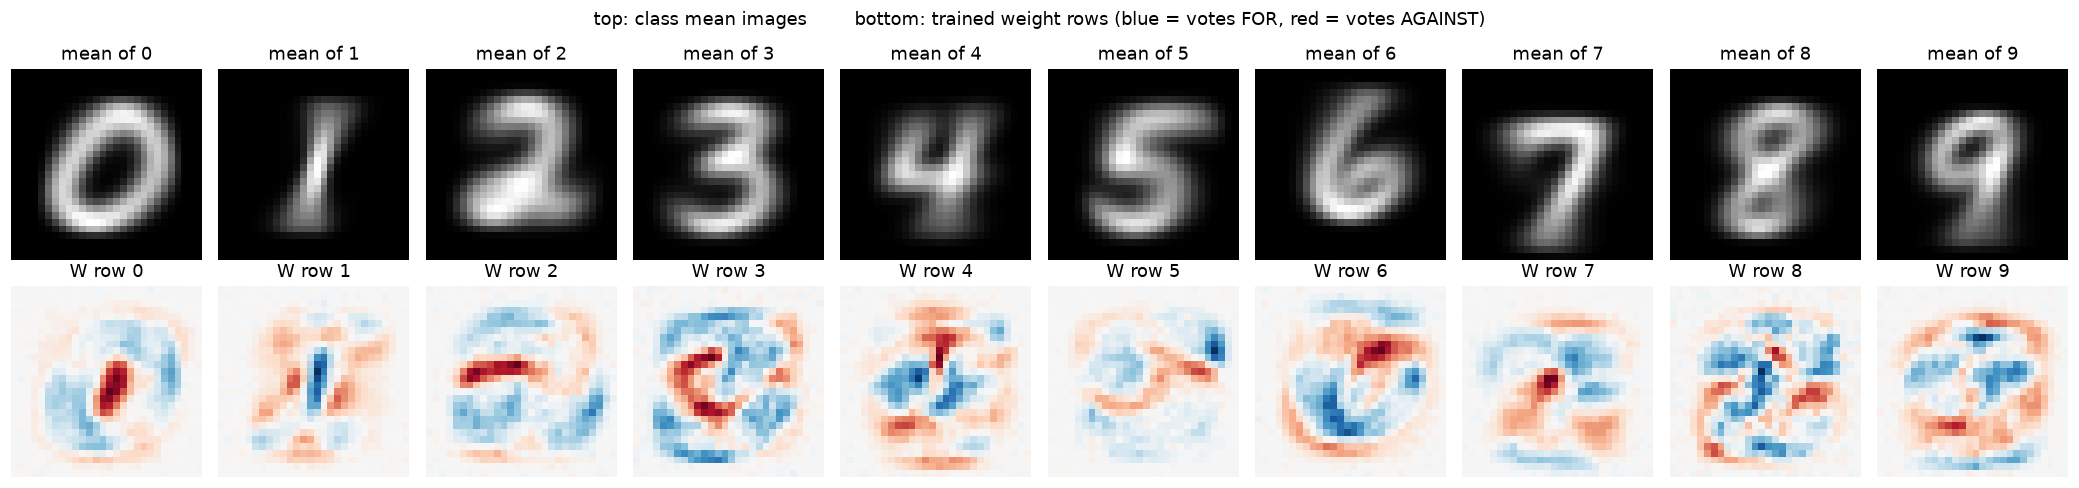

cosine similarity: trained template vs class mean
  0:+0.39   1:+0.36   2:+0.34   3:+0.35   4:+0.32   5:+0.24   6:+0.36   7:+0.35   8:+0.41   9:+0.32


In [6]:
fig, axes = plt.subplots(2, 10, figsize=(19, 4.6))
for c in range(10):
    axes[0, c].imshow(means[c].reshape(28, 28), cmap="gray")
    axes[0, c].set_title(f"mean of {c}"); axes[0, c].axis("off")
    t = model.W[c].reshape(28, 28)
    lim = np.abs(t).max()
    axes[1, c].imshow(t, cmap="RdBu", vmin=-lim, vmax=lim)
    axes[1, c].set_title(f"W row {c}"); axes[1, c].axis("off")
fig.suptitle("top: class mean images        bottom: trained weight rows (blue = votes FOR, red = votes AGAINST)")
fig.tight_layout()
save_fig(fig, FIGS / "templates_vs_means.png"); plt.show()

print("cosine similarity: trained template vs class mean")
print("  " + "   ".join(f"{c}:{model.W[c] @ means[c] / np.linalg.norm(model.W[c]) / np.linalg.norm(means[c]):+.2f}" for c in range(10)))

### How they get there

Same ten rows, replayed from checkpoint to checkpoint. Watch three things:

1. **Step 0** is Gaussian noise ($\sigma = 0.01$) — the blanks start blank.
2. By **step 1–10** the digits are already legible: a handful of batches is enough ink-averaging. Accuracy at this point is already most of the final number.
3. Afterwards the shapes barely move but the **contrast deepens** — red regions grow. Late training is mostly *learning what to suppress*, which is where the remaining accuracy comes from.

saved figure -> figures/lab01/template_evolution.png


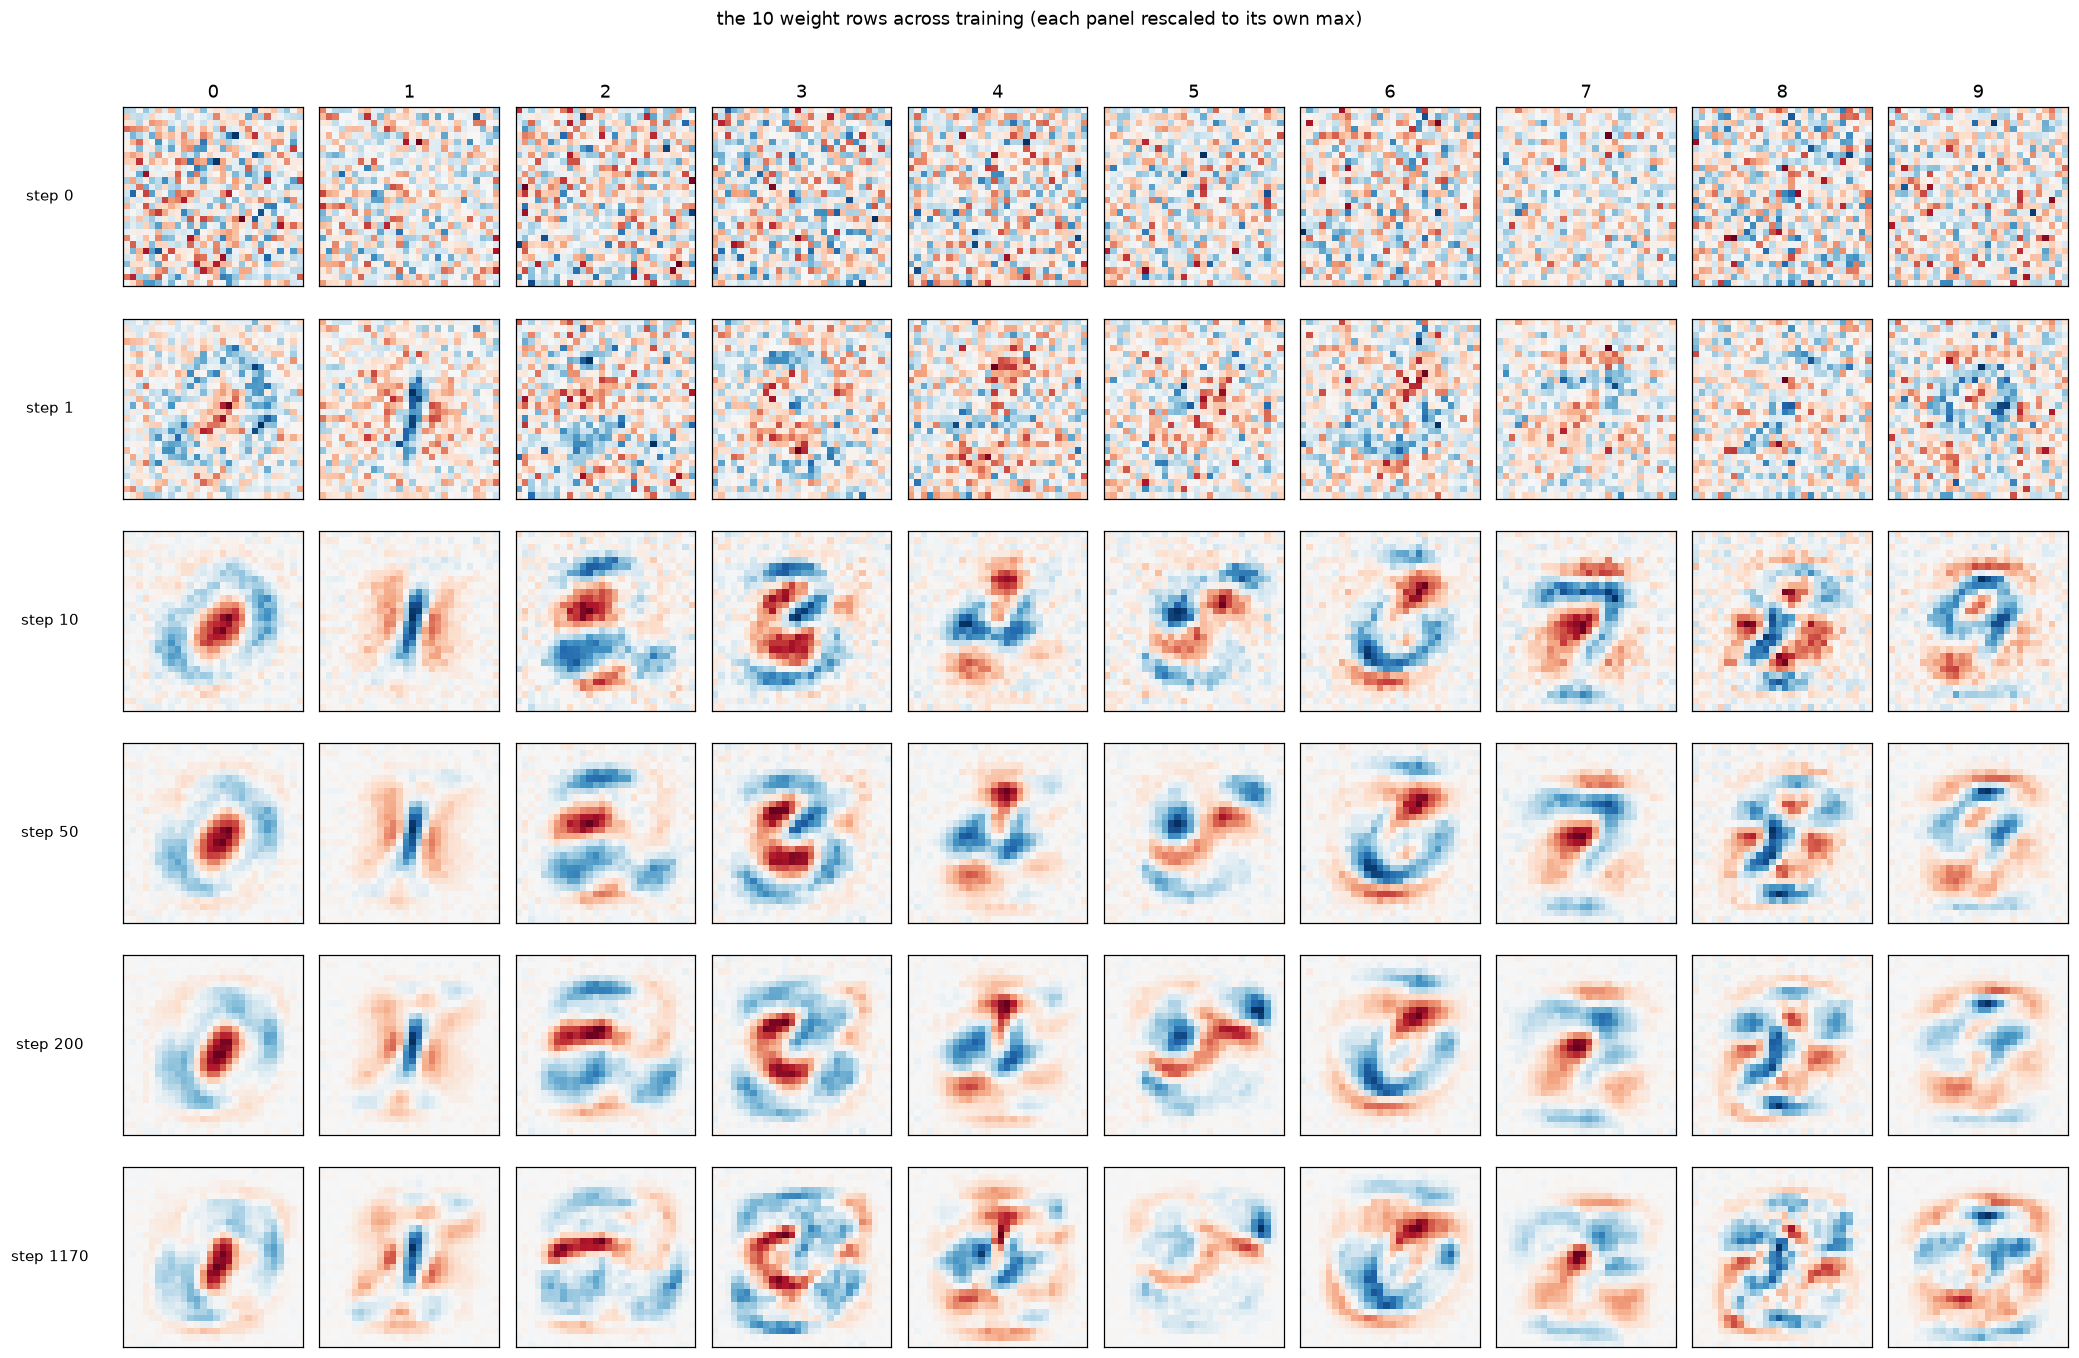

(reloaded straight from checkpoints/lab01/step_*.npz — the snapshots are real files, not replays)


In [7]:
cols = [0, 1, 10, 50, 200, n_steps]
fig, axes = plt.subplots(len(cols), 10, figsize=(19, 2.05 * len(cols)))
for r, s in enumerate(cols):
    W = snapshots[s]
    for c in range(10):
        ax = axes[r, c]
        t = W[c].reshape(28, 28)
        lim = np.abs(t).max() or 1.0
        ax.imshow(t, cmap="RdBu", vmin=-lim, vmax=lim)
        ax.set_xticks([]); ax.set_yticks([])
        if c == 0:
            ax.set_ylabel(f"step {s}", rotation=0, labelpad=48, va="center", fontsize=10)
        if r == 0:
            ax.set_title(str(c))
fig.suptitle("the 10 weight rows across training (each panel rescaled to its own max)", y=1.01)
fig.tight_layout()
save_fig(fig, FIGS / "template_evolution.png"); plt.show()
print("(reloaded straight from checkpoints/lab01/step_*.npz — the snapshots are real files, not replays)")

## 5. Where it fails — and why it fails *there*

~92–93% on test is the ceiling for a linear model on raw pixels, and the confusion matrix shows the failures are not random. The top confusions are pairs that genuinely overlap as pixel clouds — measured top offenders: 5→3 (44), 2→8 (38), 4→9 (36), 9→4 (35), 5→8 (34). All of these are *stroke-movement* differences, not pixel differences: The template model has no mechanism to fix these: "does the loop close?" or "is there a junction?" are *features*, not pixels, and a linear layer cannot form them. That missing machinery is exactly Lab 3.

saved figure -> figures/lab01/confusion.png


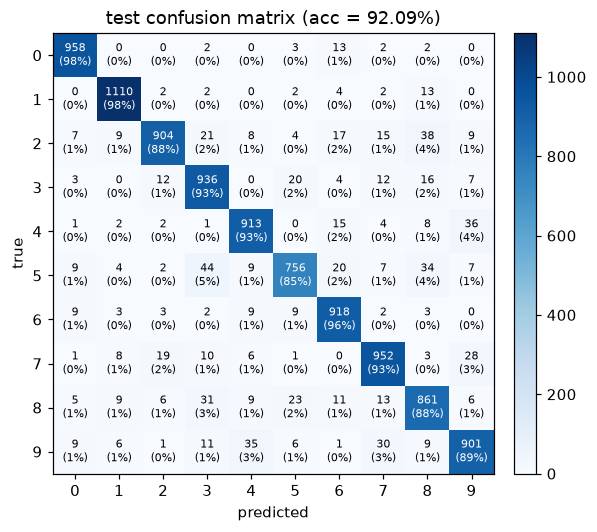

top confusions (count, true -> predicted): [(np.int64(44), 5, 3), (np.int64(38), 2, 8), (np.int64(36), 4, 9), (np.int64(35), 9, 4), (np.int64(34), 5, 8), (np.int64(31), 8, 3)]


saved figure -> figures/lab01/mistakes.png


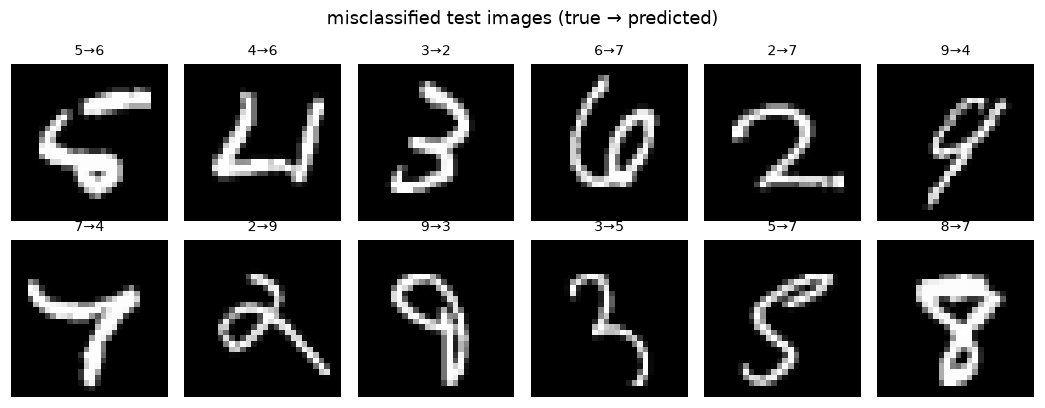

In [8]:
pred = model.predict(x_test)
cm = np.zeros((10, 10), dtype=int)
for t, p in zip(y_test, pred):
    cm[t, p] += 1

fig, ax = plt.subplots(figsize=(6, 5.2))
show_confusion(cm, list("0123456789"), ax=ax, title=f"test confusion matrix (acc = {final_acc:.2%})")
save_fig(fig, FIGS / "confusion.png"); plt.show()

off = sorted(((cm[i, j], i, j) for i in range(10) for j in range(10) if i != j), reverse=True)
print("top confusions (count, true -> predicted):", off[:6])

wrong = np.nonzero(pred != y_test)[0][:12]
fig = show_grid(x_test[wrong], titles=[f"{y_test[i]}→{pred[i]}" for i in wrong],
                ncols=6, suptitle="misclassified test images (true → predicted)")
save_fig(fig, FIGS / "mistakes.png"); plt.show()

## 6. Opening a single prediction

The score is a dot product, so it *decomposes* exactly:

$$z_c = \sum_{\text{pixel}} W_c[\text{pixel}] \cdot x[\text{pixel}] + b_c$$

The map $W_c[\text{pixel}]\cdot x[\text{pixel}]$ shows **which pixels argued for class $c$** (blue) and which argued against (red). Below: one confident correct call (a 7, p ≈ 1), and one failure — a "5" the model calls "6" with p ≈ 0.996: confidently, *inspectably* wrong — in both cases the model's "reasoning" is exposed pixel by pixel. This per-pixel decomposition is the primitive that every attribution method (saliency, integrated gradients, SHAP) is a fancier cousin of.

saved figure -> figures/lab01/explain_0.png


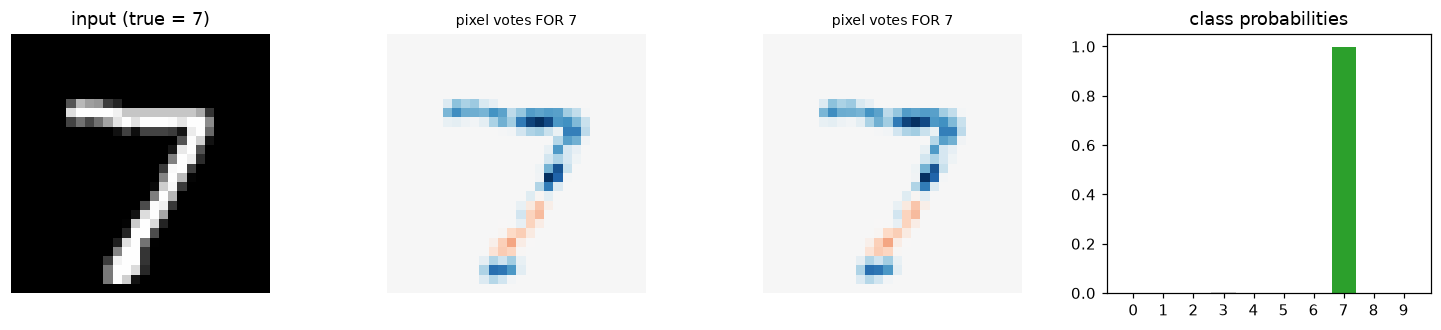

idx 0: true=7 pred=7 | p[true]=0.997 p[pred]=0.997 | logit margin z[pred]-z[true] = +0.00


saved figure -> figures/lab01/explain_8.png


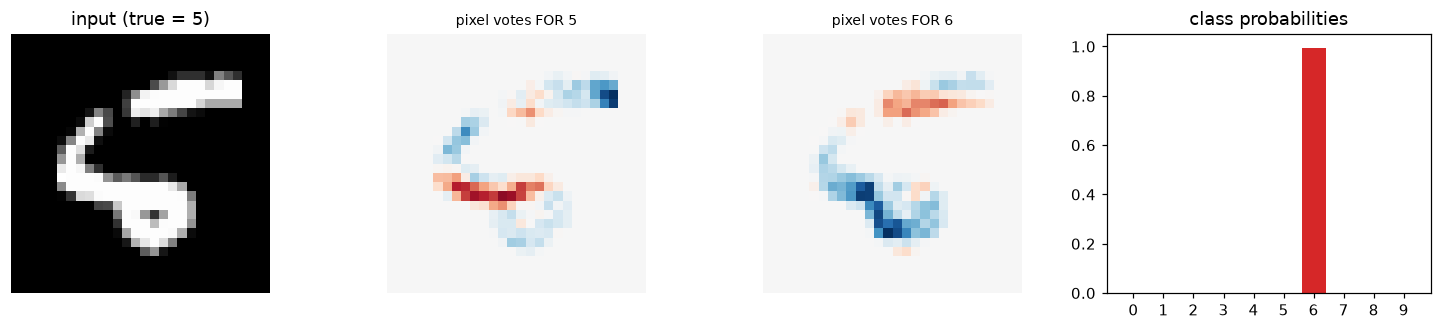

idx 8: true=5 pred=6 | p[true]=0.001 p[pred]=0.996 | logit margin z[pred]-z[true] = +6.69


In [9]:
conf = model.probs(x_test).max(axis=1)
clean_idx = int(np.nonzero((pred == y_test) & (conf > 0.99))[0][0])
fail_idx = int(np.nonzero(pred != y_test)[0][0])

for i in (clean_idx, fail_idx):
    x, yt, yp = x_test[i], int(y_test[i]), int(pred[i])
    p = model.probs(x[None])[0]
    fig, axes = plt.subplots(1, 4, figsize=(13.5, 3.1))
    axes[0].imshow(x.reshape(28, 28), cmap="gray"); axes[0].set_title(f"input (true = {yt})"); axes[0].axis("off")
    for ax, c, ttl in ((axes[1], yt, f"pixel votes FOR {yt}"), (axes[2], yp, f"pixel votes FOR {yp}")):
        m = (model.W[c] * x).reshape(28, 28)
        lim = np.abs(m).max()
        ax.imshow(m, cmap="RdBu", vmin=-lim, vmax=lim)
        ax.set_title(ttl, fontsize=9); ax.axis("off")
    colors = ["tab:green" if k == yt else "tab:red" if k == yp else "lightgrey" for k in range(10)]
    axes[3].bar(range(10), p, color=colors)
    axes[3].set_xticks(range(10)); axes[3].set_title("class probabilities")
    axes[3].set_ylim(0, 1.05)
    fig.tight_layout()
    save_fig(fig, FIGS / f"explain_{i}.png"); plt.show()
    z = model.logits(x[None])[0]
    print(f"idx {i}: true={yt} pred={yp} | p[true]={p[yt]:.3f} p[pred]={p[yp]:.3f} | logit margin z[pred]-z[true] = {z[yp] - z[yt]:+.2f}")

## 7. So what *is* a weight?

For this model, the answer fits in one sentence:

> **A row of $W$ is a matched filter: a learned photograph of its class, contrast-enhanced against the classes it gets confused with. The score is the photograph's overlap with the input; softmax is a tournament among ten overlaps.**

Every piece of that sentence is visible above: the templates (§4), the painting rule from the gradient ($\S$2), the deepening suppression halos (§4 evolution), the confusions between cloud-overlapping digits (§5), the per-pixel votes (§6).

**Where this stops working.** The "weights are pictures" trick works because the input *is* the feature space — a linear model has nowhere to hide anything. Give the network one hidden layer and rows of the first matrix stop being class photographs and become **parts**: edge detectors, stroke pieces, loop-closers. From then on you cannot read a row directly; you have to ask "what input maximally excites this neuron?" — that is activation maximization, and it is the beginning of the entire interpretability literature. That is where Lab 3 picks up.

**Worth your time (curated):**

- Olah et al., [*Feature Visualization*](https://distill.pub/2017/feature-visualization/) (Distill, 2017) — the canonical "what do neurons see" paper; our §6 is its toddler version.
- Olah et al., [*The Building Blocks of Interpretability*](https://distill.pub/2018/building-blocks/) (Distill, 2018).
- [*Zoom In: An Introduction to Circuits*](https://distill.pub/2020/circuits/zoom-in/) (Distill, 2020) — where "features" get composed into "circuits" that DO things.
- Anthropic, [*Toy Models of Superposition*](https://transformer-circuits.pub/2022/toy_model/index.html) — why features get packed into networks in entangled form (the real reason LLMs are black boxes).
- LeCun et al., [*Gradient-Based Learning Applied to Document Recognition*](http://yann.lecun.com/exdb/publis/pdf/lecun-98.pdf) (1998) — MNIST's home paper; §II still reads like modern engineering notes.

**Next:** Lab 2 runs the experiment this lab made you think of from §4 — *teach it only 1s and 2s first, then introduce 3, and watch the rows move.* (Spoiler: two-class weights turn out to be near-perfect mirror images of each other, and adding a class re-carves the old ones.)

---

### Reproduce

```bash
cd labs/ml/mnist-internals
python -m venv .venv && source .venv/bin/activate
pip install -r requirements.txt
jupyter lab        # open 01_what_do_weights_represent.ipynb, kernel: Python (mnist-internals)
```

Artifacts: `checkpoints/lab01/step_*.npz` (every snapshot above + manifest.json), `figures/lab01/*.png`.

In [10]:
print("checkpoints written this lab:")
for e in manifest(CKPT):
    print(f"  {e['name']:<14} step={str(e['step']):<6} metrics={e['metrics']}")

checkpoints written this lab:
  step_00000     step=0      metrics={'test_acc': 0.1117}
  step_00001     step=1      metrics={'test_acc': 0.5205}
  step_00002     step=2      metrics={'test_acc': 0.7309}
  step_00005     step=5      metrics={'test_acc': 0.7617}
  step_00010     step=10     metrics={'test_acc': 0.7881}
  step_00025     step=25     metrics={'test_acc': 0.8707}
  step_00050     step=50     metrics={'test_acc': 0.8883}
  step_00100     step=100    metrics={'test_acc': 0.9032}
  step_00200     step=200    metrics={'test_acc': 0.9073}
  step_00400     step=400    metrics={'test_acc': 0.916}
  step_00800     step=800    metrics={'test_acc': 0.9187}
  step_01170     step=1170   metrics={'test_acc': 0.9209}
